# 04 · Events: what was filed with the SEC this week

Varve Events is built from the EDGAR daily feed: earnings releases with their exact
acceptance time, 8-K items, insider trades (Forms 3/4/5), 13D/13G ownership stakes, late
filings and offerings. The free sample has the last 7 days of each, so the numbers in
this notebook change every time you download a fresh sample.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd
from varve_sample import load

pd.set_option("display.width", 200, "display.max_columns", 20, "display.max_colwidth", 50)

## Earnings releases: before the open or after the close?

An earnings 8-K's acceptance time (Eastern) decides which trading session first reacts.
`session` classifies it. `accepted_verified` is True when the time was confirmed against
the SEC's live data; unverifiable times are left blank rather than guessed.

In [2]:
er = load("earnings_releases")
print(f"{len(er)} earnings releases, {er['filed'].min():%d %b} – {er['filed'].max():%d %b %Y}")
er["session"].value_counts()

110 earnings releases, 09 Oct – 16 Oct 2026


session
pre_market      54
after_close     46
market_hours    10
Name: count, dtype: int64

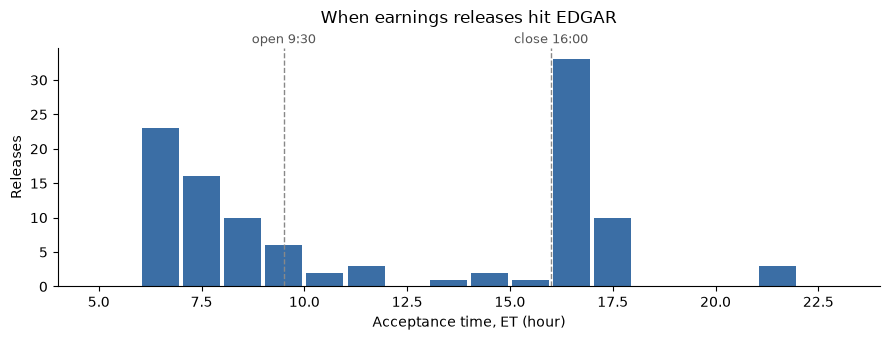

In [3]:
hour = er["accepted_et"].dt.hour + er["accepted_et"].dt.minute / 60
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(hour, bins=range(0, 25), color="#3b6ea5", rwidth=0.9)
for h, label in [(9.5, "open 9:30"), (16, "close 16:00")]:
    ax.axvline(h, color="#888", ls="--", lw=1)
    ax.text(h, 1.02, label, transform=ax.get_xaxis_transform(), ha="center",
            color="#555", fontsize=9)
ax.set_xlim(4, 24)
ax.set_xlabel("Acceptance time, ET (hour)")
ax.set_ylabel("Releases")
ax.set_title("When earnings releases hit EDGAR", pad=18)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

For an event study, a release accepted at 16:05 should be measured from the next day's
open, not that day's close. The filing date alone can't tell the two apart.

In [4]:
er.sort_values("accepted_et", ascending=False)[
    ["accepted_et", "session", "ticker", "company", "items"]].head(10)

,accepted_et,session,ticker,company,items
87,2026-10-16 17:30:16,after_close,GPRO,"GoPro, Inc.","2.02,4.02,8.01"
88,2026-10-16 17:15:39,after_close,NB,NIOCORP DEVELOPMENTS LTD,"2.02,7.01,9.01"
32,2026-10-16 16:48:59,after_close,KINS,"KINGSTONE COMPANIES, INC.","2.02,7.01,9.01"
30,2026-10-16 16:34:28,after_close,WAFD,WAFD INC,"2.02,9.01"
61,2026-10-16 16:12:31,after_close,FFIN,FIRST FINANCIAL BANKSHARES INC,"2.02,9.01"
81,2026-10-16 16:10:15,after_close,ATLO,AMES NATIONAL CORP,"2.02,9.01"
71,2026-10-16 16:06:27,after_close,FOXF,FOX FACTORY HOLDING CORP,"2.02,5.02,9.01"
91,2026-10-16 08:31:12,pre_market,LADR,Ladder Capital Corp,"2.02,9.01"
105,2026-10-16 08:05:24,pre_market,PBAM,"Private Bancorp of America, Inc.","2.02,7.01"
15,2026-10-16 06:58:21,pre_market,TRV,"TRAVELERS COMPANIES, INC.","2.02,9.01"


## Insider buying

Open-market purchases (transaction code `P`) are the insider trades usually treated as
a signal: insiders sell for many reasons, but buy for one. `value` is shares × price,
left blank where the reported price is implausible (`price_suspect`: usually a total
dollar amount typed into the price box).

In [5]:
it = load("insider_transactions")
buys = it[(it["code"] == "P") & ~it["derivative"]]

(buys.groupby(["ticker", "issuer_name"])
     .agg(dollars=("value", "sum"), insiders=("owner_cik", "nunique"),
          roles=("relationship", lambda s: ", ".join(sorted(set(s.dropna())))))
     .sort_values("dollars", ascending=False)
     .head(10)
     .assign(dollars=lambda d: d["dollars"].map("${:,.0f}".format)))

,,dollars,insiders,roles
ticker,issuer_name,,,
SAFX,"XCF Global, Inc.","$142,083,451",1,TenPercentOwner
CRBG,"Corebridge Financial, Inc.","$75,540,218",1,TenPercentOwner
GGR,Gogoro Inc.,"$35,114,298",1,Director
BBD,BANK BRADESCO,"$33,190,705",2,"Director, Officer"
BORR,Borr Drilling Ltd,"$26,559,800",2,"Director, Officer"
PEP,PEPSICO INC,"$23,686,389",1,Director
GME,GameStop Corp.,"$22,774,728",1,"Director,Officer"
QVCG,"QVC Group, Inc.","$16,697,200",1,TenPercentOwner
BPRE,Bluerock Private Real Estate Fund,"$14,025,354",3,"Director, Officer"


Several insiders buying the same stock (cluster buying) is the stronger pattern:

In [6]:
clusters = buys.groupby(["ticker", "issuer_name"])["owner_cik"].nunique()
clusters[clusters >= 2].sort_values(ascending=False).head(10)

ticker  issuer_name                      
HEI     HEICO CORP                           8
BPRE    Bluerock Private Real Estate Fund    3
GABC    GERMAN AMERICAN BANCORP, INC.        3
IMSR    Terrestrial Energy Inc. /DE/         3
REF     Reformation Inc.                     3
AHRT    AH Realty Trust, Inc.                2
ONMD    OneMedNet Corp                       2
TRXB    TRex Bio, Inc.                       2
STWI    TEG OVERSEAS, INC.                   2
RTSN    Retension Pharmaceuticals, Inc.      2
Name: owner_cik, dtype: int64

And on the sell side: how much is pre-planned? Sales under a Rule 10b5-1 plan were
scheduled in advance, so they say less about the insider's current view.

In [7]:
sells = it[(it["code"] == "S") & ~it["derivative"]]
print(f"open-market sales under a 10b5-1 plan: {sells['plan_10b5_1'].mean():.0%} of {len(sells):,}")

open-market sales under a 10b5-1 plan: 75% of 1,269


## Activist stakes (13D) and late filings

A Schedule 13D means someone crossed 5% and may seek to influence the company; `activist`
separates those from passive 13G holders. An NT 10-Q or NT 10-K means a company told the
SEC it would miss its filing deadline, often a warning sign.

In [8]:
own = load("ownership_filings")
own[own["activist"] & ~own["amendment"]][["filed", "ticker", "company", "filer_name", "form"]].head(10)

,filed,ticker,company,filer_name,form
0,2026-10-09,GWLL,"GOLDENWELL BIOTECH, INC.",NaN,SCHEDULE 13D
1,2026-10-09,NCMI,"National CineMedia, Inc.",NaN,SCHEDULE 13D
2,2026-10-09,DPU,Top KingWin Ltd,Xu Ruilin,SCHEDULE 13D
3,2026-10-09,OMTK,Omnitek Engineering Corp,NaN,SCHEDULE 13D
4,2026-10-09,VDTA,Vertical Data Inc.,Nickel Jesse,SCHEDULE 13D
5,2026-10-09,VDTA,Vertical Data Inc.,NaN,SCHEDULE 13D
6,2026-10-09,WBUY,WEBUY GLOBAL LTD,NaN,SCHEDULE 13D
64,2026-10-13,BORR,Borr Drilling Ltd,Drew Holdings Ltd,SCHEDULE 13D
65,2026-10-13,RADB,TETE Technologies Inc,NaN,SCHEDULE 13D
66,2026-10-13,CRCUF,Canagold Resources Ltd.,NaN,SCHEDULE 13D


In [9]:
late = load("late_filings")
late[["filed", "form", "ticker", "company"]].head(10)

,filed,form,ticker,company
0,2026-10-14,NT 10-Q,RMCF,"Rocky Mountain Chocolate Factory, Inc."
1,2026-10-15,NT 10-Q,AUSI,AURA SYSTEMS INC
2,2026-10-15,NT 10-Q,KARX,Karbon-X Corp.
3,2026-10-13,NT 10-Q,ECXJ,"CXJ GROUP CO., Ltd"
4,2026-10-15,NT 10-Q,PUBC,Purebase Corp
5,2026-10-15,NT 10-Q,AITX,Artificial Intelligence Technology Solutions Inc.
6,2026-10-15,NT 10-Q,UPYY,UPAY
7,2026-10-15,NT 10-Q,TMGI,"Transglobal Management Group, Inc."
8,2026-10-16,NT 10-Q,HSTA,Hestia Insight Inc.
9,2026-10-16,NT 10-Q,NaN,MYX Inc.


## 8-K items

Each current report is split into its items, so you can filter for what matters to
you: 5.02 (executive departures), 1.01 (material agreements), 2.01 (completed
acquisitions), 4.02 (non-reliance: previously issued financials can't be relied on).

In [10]:
cr = load("current_reports")
cr.groupby(["item", "item_desc"]).size().sort_values(ascending=False).head(12)

item  item_desc                                                            
9.01  Financial statements and exhibits                                        723
8.01  Other events                                                             304
7.01  Regulation FD disclosure                                                 265
1.01  Entry into a material definitive agreement                               215
5.02  Departure/appointment of directors or officers; compensation             183
2.02  Results of operations and financial condition (earnings)                 110
2.03  Creation of a direct financial obligation                                104
3.02  Unregistered sales of equity securities                                   74
5.07  Submission of matters to a vote of security holders                       47
5.03  Amendments to articles of incorporation or bylaws; fiscal year change     45
3.01  Notice of delisting or failure to satisfy listing rule                    29
1.02  Termi

In [11]:
cr[cr["item"].astype(str) == "4.02"][["filed", "ticker", "company", "item_desc"]]

,filed,ticker,company,item_desc
1078,2026-10-13,EONR,EON Resources Inc.,Non-reliance on previously issued financial st...
1346,2026-10-15,ATVK,"Globaltek Ventures, Inc.",Non-reliance on previously issued financial st...
1781,2026-10-16,GPRO,"GoPro, Inc.",Non-reliance on previously issued financial st...
2070,2026-10-16,ROLR,"High Roller Technologies, Inc.",Non-reliance on previously issued financial st...


## Next

The full Varve Events database has the history (insider trades since 2006, earnings
release times since 2004, 13D/G since the 1990s), updated every weekday evening, and
includes Corporate Actions (splits with ex-dates, listings and delistings). See
[varvedata.com/events.html](https://varvedata.com/events.html).